**Predição de diabetes utilizando Redes Neurais Artificiais (Deep Learning)**

Este projeto tem como objetivo colocar em prática os conhecimentos adquiridos na minha pós-graduação em Ciência de Dados Aplicada à Saúde, por meio do uso de Deep Learning e redes neurais. Mais especificamente, foi utilizada uma rede neural feedforward (ou MLP — Multilayer Perceptron).

Para este projeto, selecionei um dataset de diabetes com o objetivo de realizar a predição de casos com e sem diabetes.

Inicialmente, foi realizada a limpeza dos dados, incluindo a remoção de registros duplicados, seguida de uma análise exploratória. Posteriormente, foram treinados três modelos, cujos desempenhos foram comparados utilizando os dados de validação. Por fim, o modelo que apresentou o melhor desempenho na validação foi selecionado e avaliado no conjunto de teste. 

In [ ]:
import sys
!{sys.executable} -m pip install plotly

In [ ]:
import sys
!{sys.executable} -m pip install tensorflow

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import warnings
import plotly.express as px
import tensorflow as tf

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')

In [82]:
def reset_seeds():
    os.environ['PYTHONHASHSEED'] = str(42)
    tf.random.set_seed(42)
    np.random.seed(42)
    random.seed(42)

In [83]:
data = pd.read_csv('diabetes_prediction_dataset.csv')

In [84]:
data

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [85]:
data.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [86]:
data.duplicated().sum()

np.int64(3854)

In [87]:
data.drop_duplicates(inplace=True)

In [88]:
data.dtypes

gender                     str
age                    float64
hypertension             int64
heart_disease            int64
smoking_history            str
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

In [89]:
var_cat = data[['gender', 'heart_disease', 'smoking_history', 'hypertension', 'diabetes']]
var_num = data[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']]

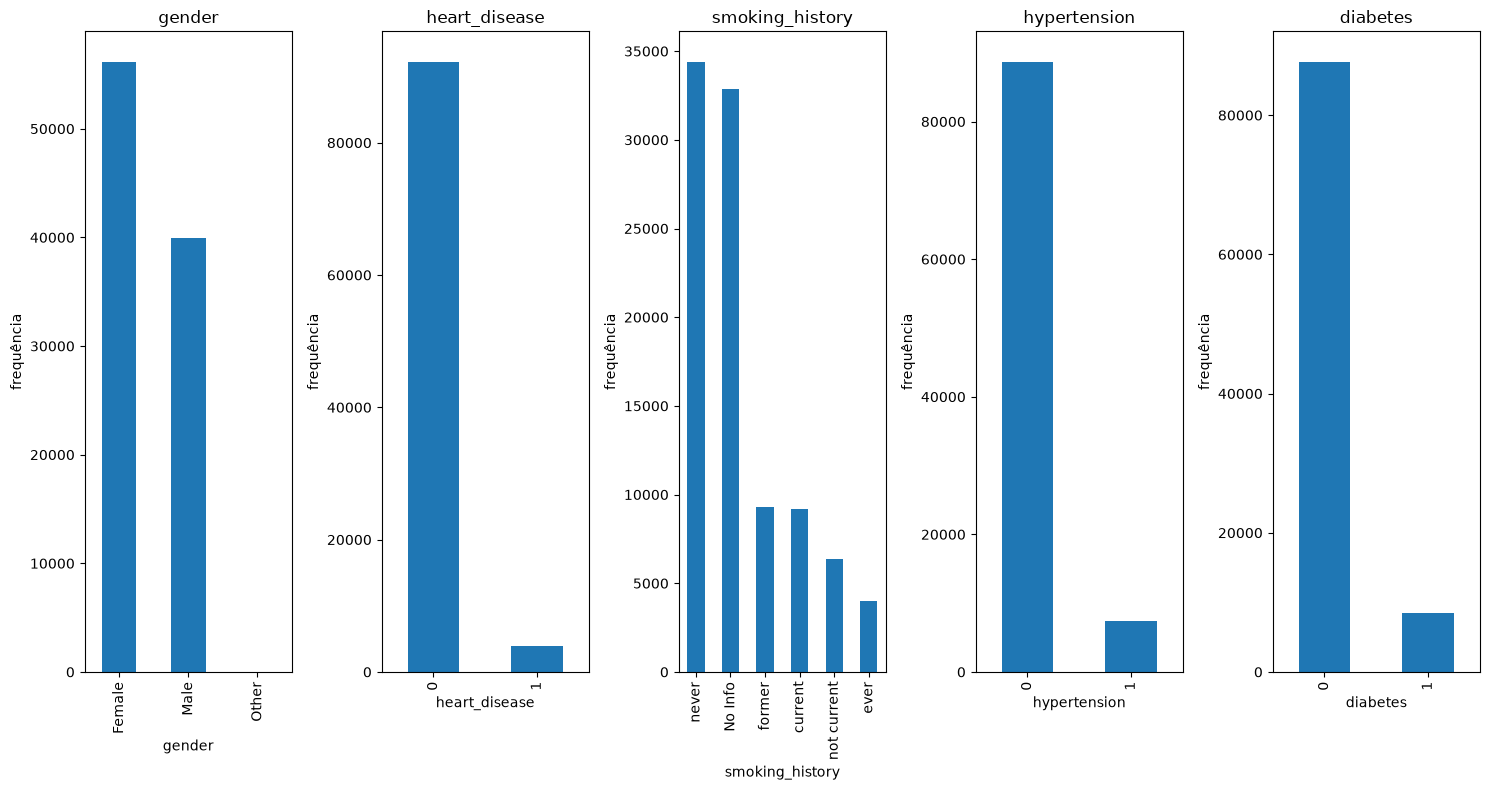

In [90]:
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
for coluna, ax in zip(var_cat.columns, axes):
    var_cat[coluna].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel(coluna)
    ax.set_ylabel('frequência')
plt.tight_layout()
plt.show()

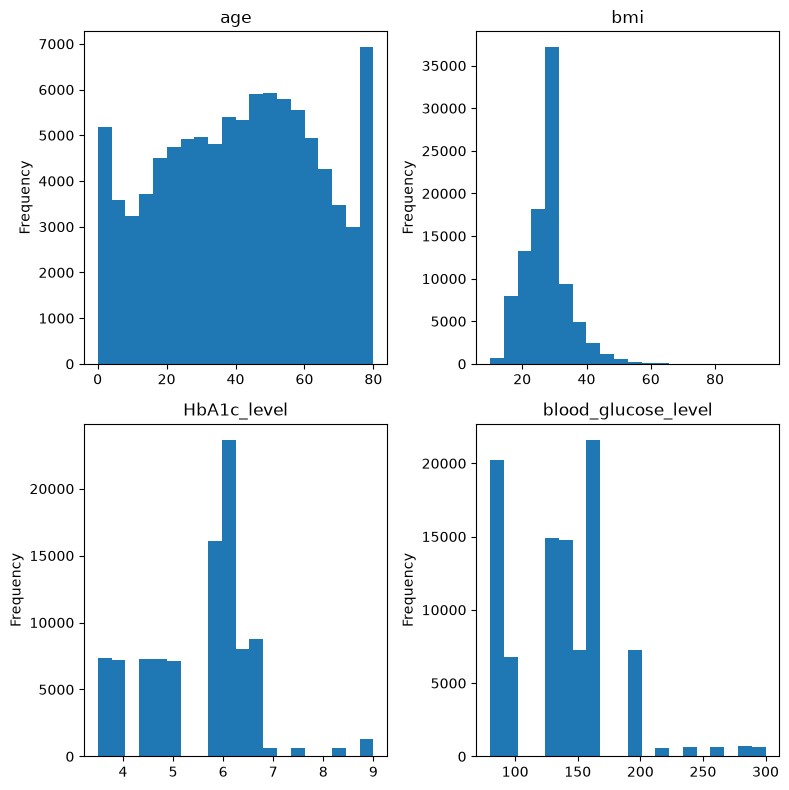

In [91]:
fig, axes = plt.subplots(2, 2, figsize=(8,8))
for coluna, ax in zip(var_num.columns, axes.flatten()):
    var_num[coluna].plot(kind='hist', bins=20, ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()
    

In [92]:
var_num.describe().T

,count,mean,std,min,25%,50%,75%,max
age,96146.0,41.794326,22.462948,0.08,24.0,43.00,59.00,80.00
bmi,96146.0,27.321461,6.767716,10.01,23.4,27.32,29.86,95.69
HbA1c_level,96146.0,5.532609,1.073232,3.50,4.8,5.80,6.20,9.00
blood_glucose_level,96146.0,138.218231,40.909771,80.00,100.0,140.00,159.00,300.00


In [93]:
for coluna in var_num.columns:
    Q1 = var_num[coluna].quantile(0.25)
    Q3 = var_num[coluna].quantile(0.75)

    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    abaixo = (var_num[coluna] < limite_inferior).sum()
    acima = (var_num[coluna] > limite_superior).sum()

    print(f'\n{coluna}')
    print(f'Abaixo do limite inferior: {abaixo}')
    print(f'Acima do limite superior: {acima}')


age
Abaixo do limite inferior: 0
Acima do limite superior: 0

bmi
Abaixo do limite inferior: 414
Acima do limite superior: 4940

HbA1c_level
Abaixo do limite inferior: 0
Acima do limite superior: 1312

blood_glucose_level
Abaixo do limite inferior: 0
Acima do limite superior: 2031


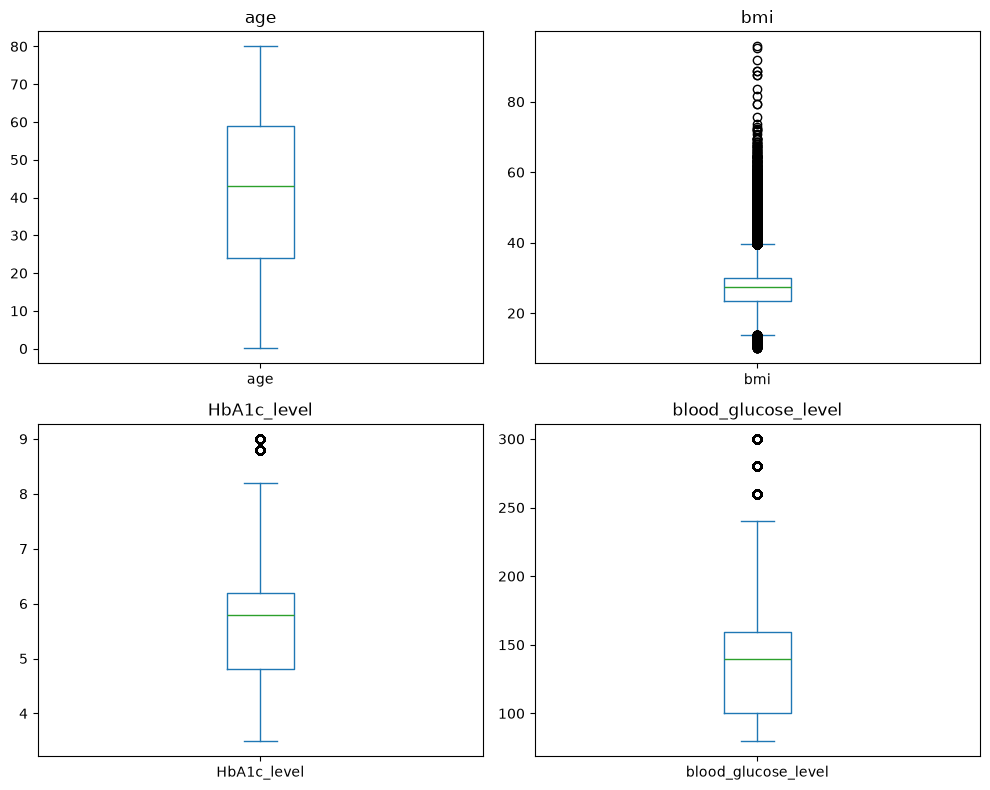

In [94]:
fig, axes  = plt.subplots(2,2, figsize=(10, 8))
for coluna, ax in zip(var_num.columns, axes.flatten()):
    var_num[coluna].plot(kind='box', ax=ax)
    ax.set_title(coluna)
plt.tight_layout()
plt.show()

In [95]:
data['diabetes'].value_counts()

diabetes
0    87664
1     8482
Name: count, dtype: int64

In [96]:
data['diabetes'].value_counts(normalize=True) * 100

diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64

In [97]:
data.groupby('diabetes')[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']].mean()

,age,bmi,HbA1c_level,blood_glucose_level
diabetes,,,,
0,39.943229,26.869003,5.396936,132.818489
1,60.925961,31.997755,6.934827,194.026173


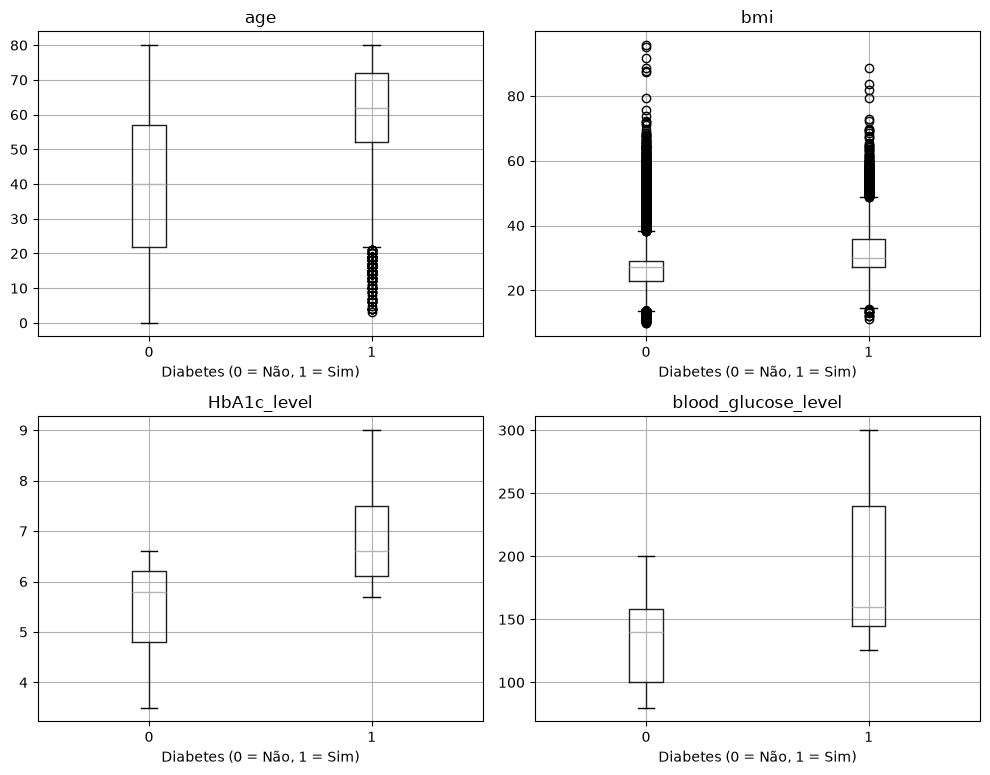

In [98]:
fig, axes = plt.subplots(2, 2, figsize=(10,8))
for coluna, ax in zip(var_num.columns, axes.flatten()):
    data.boxplot(column=coluna, by='diabetes', ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel('Diabetes (0 = Não, 1 = Sim)')

plt.suptitle('')
plt.tight_layout()
plt.show()

**IDADE (Age):** Pessoas com diabetes tendem a ser mais velhas que pessoas sem diabetes, no entanto, há uma quantidade significativa de pessoas jovens com diabetes. 

**IMC (BMI):** Pessoas com diabetes possuem uma mediana ligeiramente mais elevada em comparação à pessoas sem diabetes. Entretanto, há bastante sobreposição entre os grupos e uma quantidade considerável de possíveis outliers em ambos os grupos, principalmente nos valores mais elevados.

**Nível de hemoglobina glicada (HbA1c_level):** Embora há uma diferença ligeira em termos de numeros absolutos na mediana entre os dois grupos, essas diferenças podem ser clinicamente relevantes. Chama atenção o fato de que a mediana do grupo sem diabetes tem valor de aproximadamente 5,8%, valor que já se encontra na faixa pré-diabetes segundo os critérios clínicos de referência. Isso nos lembra que a classificação binária do dataset não necessariamente representa todas as intermediárias relacionadas a diabetes

**Nível de glicose no sangue (blood_glucose_level):** O grupo sem diabetes apresenta uma mediana de aproximadamente 140 mg/dL, enquanto o grupo com diabetes apresenta uma mediana aproximada de 160 mg/dL. Além disso, o grupo com diabetes apresenta maior dispersão nos valores de glicose, indicando uma distribuição mais variável.

In [99]:
var_cat_bin = data[['heart_disease', 'hypertension']]
var_cat_nom = data[['gender',  'smoking_history']]

In [100]:
data.groupby('diabetes')[var_cat_bin.columns].mean() * 100

,heart_disease,hypertension
diabetes,,
0,3.029750,6.131365
1,14.937515,24.593256


**O grupo com diabetes apresenta proporções significativamente maiores de doença cardiaca e hipertensão em comparação ao grupo sem diabetes**

In [101]:
for coluna in var_cat_nom.columns:
    print(pd.crosstab(data['diabetes'], data[coluna], normalize='index') * 100)

gender       Female       Male     Other
diabetes                                
0         58.991148  40.988319  0.020533
1         52.428672  47.571328  0.000000
smoking_history    No Info    current      ever     former      never  \
diabetes                                                                
0                35.866490   9.409792  4.022176   8.793804  35.431876   
1                17.036076  11.176609  5.564725  18.745579  39.342136   

smoking_history  not current  
diabetes                      
0                   6.475862  
1                   8.134874  


**Esses números indicam diferenças na distribuição do histórico de tabagismo entre os grupos, com destaque para a maior proporção de pessoas que já fumaram (former) no grupo com diabetes. Também há uma maior proporção de homens no grupo com diabetes em comparação ao grupo sem diabetes.**

In [121]:
X = data.drop(columns=['diabetes'])
y = data['diabetes']

print(X.shape)
print(y.shape)

(96146, 8)
(96146,)


In [122]:
print(y.value_counts(normalize='True') * 100)

diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


In [123]:
reset_seeds()

# Separação entre treino e teste
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Separação entre treino e validação
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [124]:
print("X_train:", X_train_raw.shape)
print("X_val:", X_val_raw.shape)
print("X_test:", X_test_raw.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (61532, 8)
X_val: (15384, 8)
X_test: (19230, 8)
y_train: (61532,)
y_val: (15384,)
y_test: (19230,)


In [125]:
print(y_train.value_counts(normalize=True) * 100)
print(y_val.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)  

diabetes
0    91.176949
1     8.823051
Name: proportion, dtype: float64
diabetes
0    91.179147
1     8.820853
Name: proportion, dtype: float64
diabetes
0    91.180447
1     8.819553
Name: proportion, dtype: float64


In [126]:
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_cat = encoder.fit_transform(X_train_raw[var_cat_nom.columns])
X_val_cat = encoder.transform(X_val_raw[var_cat_nom.columns])
X_test_cat = encoder.transform(X_test_raw[var_cat_nom.columns])

In [127]:
scaler = StandardScaler()

In [128]:
X_train_num = scaler.fit_transform(X_train_raw[var_num.columns])
X_val_num = scaler.transform(X_val_raw[var_num.columns])
X_test_num = scaler.transform(X_test_raw[var_num.columns])

print(X_train_num.shape)
print(X_val_num.shape)
print(X_test_num.shape)

(61532, 4)
(15384, 4)
(19230, 4)


In [129]:
X_train_bin = X_train_raw[var_cat_bin.columns].values
X_val_bin = X_val_raw[var_cat_bin.columns].values
X_test_bin = X_test_raw[var_cat_bin.columns].values

In [133]:
X_train_final = np.concatenate([X_train_num, X_train_cat, X_train_bin], axis=1)

X_val_final = np.concatenate([X_val_num, X_val_cat, X_val_bin], axis=1)

X_test_final = np.concatenate([X_test_num, X_test_cat, X_test_bin], axis=1)

print(X_train_final.shape)
print(X_val_final.shape)
print(X_test_final.shape)

(61532, 15)
(15384, 15)
(19230, 15)


In [134]:
classes = np.unique(y_train)

pesos = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, pesos))
print(class_weights)

{np.int64(0): np.float64(0.5483842218776179), np.int64(1): np.float64(5.666973659974213)}


In [135]:
reset_seeds()

model = Sequential([
    Input(shape=(X_train_final.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1,activation='sigmoid')])

In [136]:
model.compile(
    optimizer = 'adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

In [137]:
print("X_train:", X_train_final.shape)
print("X_val:", X_val_final.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (61532, 15)
X_val: (15384, 15)
y_train: (61532,)
y_val: (15384,)


**Treinamento do primeiro modelo:**

In [138]:
history = model.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_final, y_val),
    class_weight=class_weights
)

Epoch 1/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8771 - loss: 0.2504 - val_accuracy: 0.8738 - val_loss: 0.2460
Epoch 2/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8888 - loss: 0.2050 - val_accuracy: 0.8932 - val_loss: 0.2032
Epoch 3/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8928 - loss: 0.1928 - val_accuracy: 0.9031 - val_loss: 0.1889
Epoch 4/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8953 - loss: 0.1889 - val_accuracy: 0.9065 - val_loss: 0.1854
Epoch 5/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8968 - loss: 0.1867 - val_accuracy: 0.9076 - val_loss: 0.1854
Epoch 6/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8978 - loss: 0.1856 - val_accuracy: 0.9078 - val_loss: 0.1820
Epoch 7/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8980 - loss: 0.1845 - val_accuracy: 0.9083 - val_loss: 0.1798
Epoch 8/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8986 - loss: 0.1837 - 

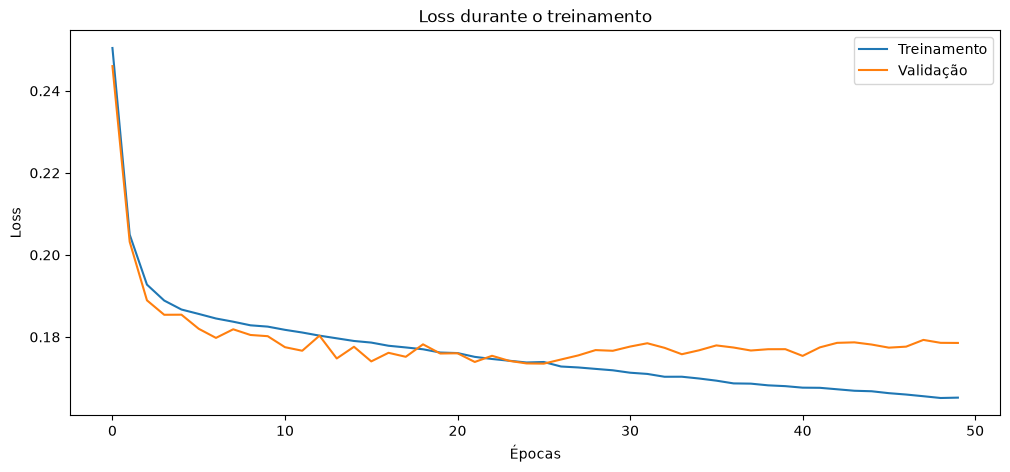

In [139]:
plt.figure(figsize=(12,5))
plt.plot(history.history['loss'], label = 'Treinamento')
plt.plot(history.history['val_loss'], label='Validação')

plt.title('Loss durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.show()

**Podemos observar, por meio dos valores de `val_loss` e do gráfico, que, a partir de aproximadamente a época 25, o modelo começou a apresentar sinais de overfitting.**

**Até aproximadamente a época 24, ambas as curvas diminuem consideravelmente. Entre as épocas 24 e 50, a curva de treinamento continua diminuindo lentamente, enquanto a curva de validação apresenta uma leve tendência de subida, com algumas oscilações, mantendo-se relativamente estável.**

**Irei implementar o Early Stopping para interromper o treinamento quando a perda de validação deixar de melhorar, recuperando os pesos da melhor época. Depois, treinarei um segundo modelo para comparar os resultados com o primeiro.**

In [140]:
early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience = 5,
    restore_best_weights=True
)

In [141]:
reset_seeds()
model_2 = Sequential([
    Input(shape=(X_train_final.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')])

model_2.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

**Treinamento do segundo modelo:**

In [165]:
history_2 = model_2.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_final, y_val),
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8988 - loss: 0.1817 - val_accuracy: 0.9114 - val_loss: 0.1735
Epoch 2/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8999 - loss: 0.1811 - val_accuracy: 0.9119 - val_loss: 0.1732
Epoch 3/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9001 - loss: 0.1807 - val_accuracy: 0.9108 - val_loss: 0.1737
Epoch 4/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9002 - loss: 0.1801 - val_accuracy: 0.9110 - val_loss: 0.1737
Epoch 5/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9010 - loss: 0.1793 - val_accuracy: 0.9135 - val_loss: 0.1722
Epoch 6/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9011 - loss: 0.1787 - val_accuracy: 0.9119 - val_loss: 0.1719
Epoch 7/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9010 - loss: 0.1783 - val_accuracy: 0.9089 - val_loss: 0.1755
Epoch 8/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9015 - loss: 0.1777 - 

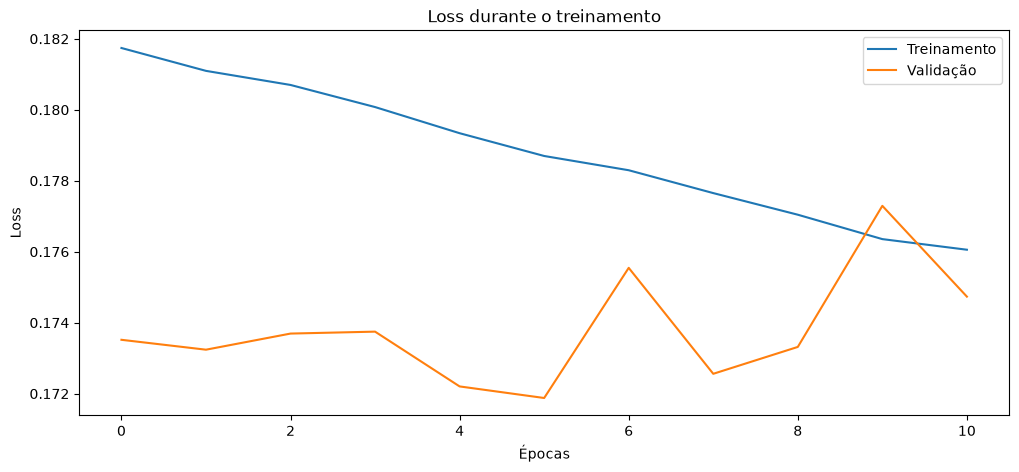

In [166]:
plt.figure(figsize=(12,5))
plt.plot(history_2.history['loss'], label = 'Treinamento')
plt.plot(history_2.history['val_loss'], label='Validação')

plt.title('Loss durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [168]:
print('Primeiro treinamento:')
print('Melhor época:', np.argmin(history.history['val_loss']) + 1)
print('Menor val_loss:', min(history.history['val_loss']))

print('\nSegundo treinamento:')
print('Melhor época:', np.argmin(history_2.history['val_loss']) + 1)
print('Menor val_loss:', min(history_2.history['val_loss']))

Primeiro treinamento:
Melhor época: 26
Menor val_loss: 0.17349554598331451

Segundo treinamento:
Melhor época: 6
Menor val_loss: 0.17187747359275818


**Ao comparar os dois treinamentos, observamos que o segundo apresentou uma menor perda de validação (0.1719), em relação ao primeiro (0.1735). Além disso, o segundo atingiu seu melhor resultado na época 6, enquanto o primeiro alcançou o menor valor na época 26.**

**Apesar da pequena diferença entre os valores, o segundo treinamento apresentou uma melhora na `val_loss` e precisou de menos épocas para atingir seu melhor resultado.**

In [169]:
tf.config.experimental.enable_op_determinism()

In [170]:
reset_seeds()
model_3 = Sequential([
    Input(shape=(X_train_final.shape[1],)),
    Dense(64, activation = 'relu'),
    Dense(32, activation = 'relu'),
    Dense(1, activation = 'sigmoid')])

model_3.compile(
    optimizer='adam',
    loss='binary_crossentropy', 
    metrics =['accuracy'])


**Treinamento do terceiro modelo:**

In [171]:
early_stopping_3 = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True)
history_3 = model_3.fit(
    X_train_final,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_final, y_val),
    class_weight=class_weights,
    callbacks=[early_stopping_3]
)

Epoch 1/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8771 - loss: 0.2504 - val_accuracy: 0.8738 - val_loss: 0.2460
Epoch 2/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8888 - loss: 0.2050 - val_accuracy: 0.8932 - val_loss: 0.2032
Epoch 3/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8928 - loss: 0.1928 - val_accuracy: 0.9031 - val_loss: 0.1889
Epoch 4/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8953 - loss: 0.1889 - val_accuracy: 0.9065 - val_loss: 0.1854
Epoch 5/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8968 - loss: 0.1867 - val_accuracy: 0.9076 - val_loss: 0.1854
Epoch 6/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8978 - loss: 0.1856 - val_accuracy: 0.9078 - val_loss: 0.1820
Epoch 7/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8980 - loss: 0.1845 - val_accuracy: 0.9083 - val_loss: 0.1798
Epoch 8/50
1923/1923 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8986 - loss: 0.1837 - 

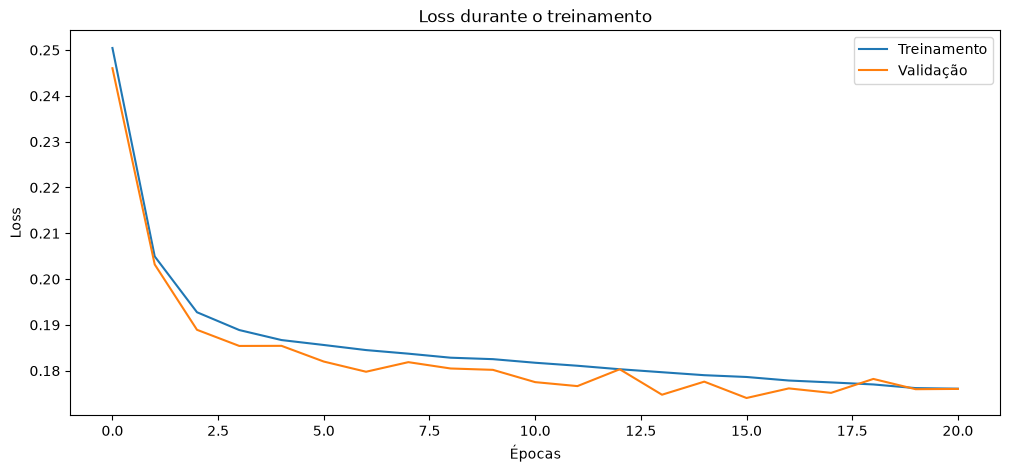

In [172]:
plt.figure(figsize=(12,5))
plt.plot(history_3.history['loss'], label = 'Treinamento')
plt.plot(history_3.history['val_loss'], label='Validação')

plt.title('Loss durante o treinamento')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [173]:
print('Primeiro treinamento:')
print('Melhor época:', np.argmin(history.history['val_loss']) + 1)
print('Menor val_loss:', min(history.history['val_loss']))

print('\nSegundo treinamento:')
print('Melhor época:', np.argmin(history_2.history['val_loss']) + 1)
print('Menor val_loss:', min(history_2.history['val_loss']))

print('\nTerceiro treinamento:')
print('Melhor época:', np.argmin(history_3.history['val_loss']) + 1)
print('Menor val_loss:', min(history_3.history['val_loss']))

Primeiro treinamento:
Melhor época: 26
Menor val_loss: 0.17349554598331451

Segundo treinamento:
Melhor época: 6
Menor val_loss: 0.17187747359275818

Terceiro treinamento:
Melhor época: 16
Menor val_loss: 0.17404049634933472


**Ao comparar os três treinamentos, observamos que o segundo apresentou a menor perda de validação (0.1719), enquanto o primeiro e o terceiro apresentaram valores de 0.1735 e 0.1740, respectivamente.**

**Dessa forma, considerando a `val_loss` como critério de comparação, o segundo treinamento apresentou o melhor resultado. Entretanto, as diferenças entre os valores são pequenas. Irei analisar outras métricas para uma avaliação mais completa dos modelos.**

In [174]:
# Primeiro modelo
y_val_prob_1 = model.predict(X_val_final)
y_val_pred_1 = (y_val_prob_1 >= 0.5).astype(int)

# Segundo modelo
y_val_prob_2 = model_2.predict(X_val_final)
y_val_pred_2 = (y_val_prob_2 >= 0.5).astype(int)

# Terceiro modelo
y_val_prob_3 = model_3.predict(X_val_final)
y_val_pred_3 = (y_val_prob_3 >= 0.5).astype(int)

481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 985us/step
481/481 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


In [175]:
# Primeiro modelo
print('Primeiro modelo')
print('Accuracy:', accuracy_score(y_val, y_val_pred_1))
print('Precision:', precision_score(y_val, y_val_pred_1))
print('Recall:', recall_score(y_val, y_val_pred_1))
print('F1-score:', f1_score(y_val, y_val_pred_1))

# Segundo modelo
print('\nSegundo modelo')
print('Accuracy:', accuracy_score(y_val, y_val_pred_2))
print('Precision:', precision_score(y_val, y_val_pred_2))
print('Recall:', recall_score(y_val, y_val_pred_2))
print('F1-score:', f1_score(y_val, y_val_pred_2))

# Terceiro modelo
print('\nTerceiro modelo')
print('Accuracy:', accuracy_score(y_val, y_val_pred_3))
print('Precision:', precision_score(y_val, y_val_pred_3))
print('Recall:', recall_score(y_val, y_val_pred_3))
print('F1-score:', f1_score(y_val, y_val_pred_3))

Primeiro modelo
Accuracy: 0.906786271450858
Precision: 0.4845691382765531
Recall: 0.8909358879882093
F1-score: 0.6277258566978193

Segundo modelo
Accuracy: 0.9118564742589703
Precision: 0.5002055076037814
Recall: 0.8968312453942521
F1-score: 0.6422163588390501

Terceiro modelo
Accuracy: 0.9126365054602185
Precision: 0.5026715988491575
Recall: 0.9012527634487841
F1-score: 0.6453825857519789


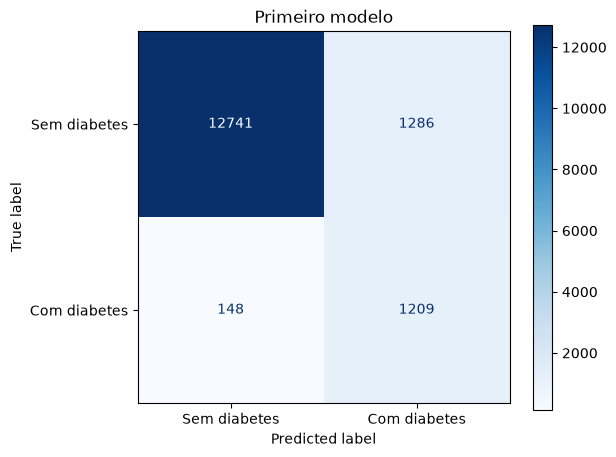

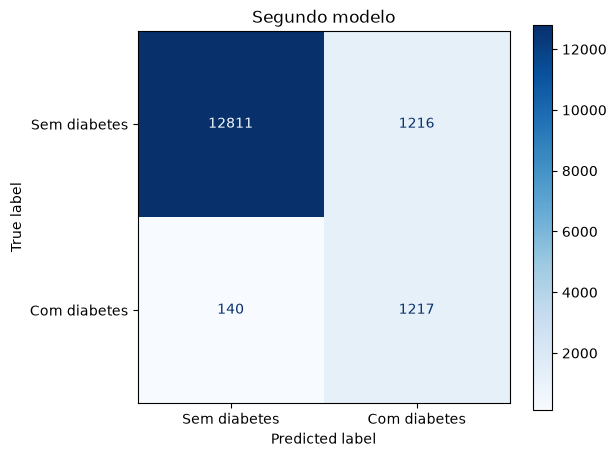

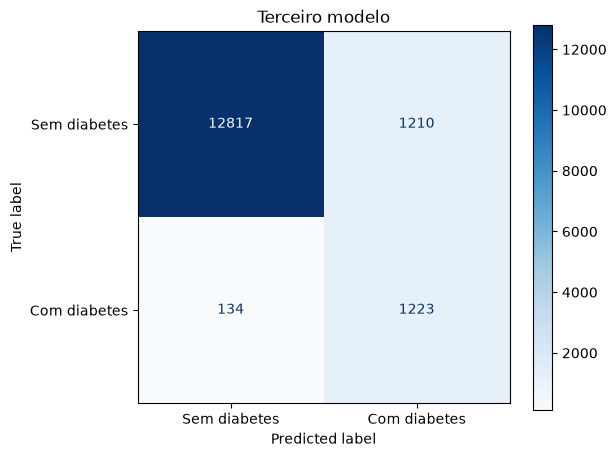

In [176]:
# Primeiro modelo
cm_1 = confusion_matrix(y_val, y_val_pred_1)

# Segundo modelo
cm_2 = confusion_matrix(y_val, y_val_pred_2)

# Terceiro modelo
cm_3 = confusion_matrix(y_val, y_val_pred_3)

# Primeiro modelo
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_1,
    display_labels=['Sem diabetes', 'Com diabetes']
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Primeiro modelo')
plt.show()

# Segundo modelo
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_2,
    display_labels=['Sem diabetes', 'Com diabetes']
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Segundo modelo')
plt.show()

# Terceiro modelo
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_3,
    display_labels=['Sem diabetes', 'Com diabetes']
)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Terceiro modelo')
plt.show()

In [177]:
print('Primeiro modelo')
print(classification_report(
    y_val, y_val_pred_1,
    target_names=['Sem diabetes', 'Com diabetes']
))

print('Segundo modelo')
print(classification_report(
    y_val, y_val_pred_2,
    target_names=['Sem diabetes', 'Com diabetes']
))

print('Terceiro modelo')
print(classification_report(
    y_val, y_val_pred_3,
    target_names=['Sem diabetes', 'Com diabetes']
))

Primeiro modelo
              precision    recall  f1-score   support

Sem diabetes       0.99      0.91      0.95     14027
Com diabetes       0.48      0.89      0.63      1357

    accuracy                           0.91     15384
   macro avg       0.74      0.90      0.79     15384
weighted avg       0.94      0.91      0.92     15384

Segundo modelo
              precision    recall  f1-score   support

Sem diabetes       0.99      0.91      0.95     14027
Com diabetes       0.50      0.90      0.64      1357

    accuracy                           0.91     15384
   macro avg       0.74      0.91      0.80     15384
weighted avg       0.95      0.91      0.92     15384

Terceiro modelo
              precision    recall  f1-score   support

Sem diabetes       0.99      0.91      0.95     14027
Com diabetes       0.50      0.90      0.65      1357

    accuracy                           0.91     15384
   macro avg       0.75      0.91      0.80     15384
weighted avg       0.95    

**Os três modelos apresentaram resultados bastante semelhantes nos dados de validação. O terceiro modelo obteve o melhor F1-score para a classe com diabetes, enquanto que nas outras métricas apresentou valores muito próximos aos do segundo modelo. Considerando o conjunto de métricas, o terceiro modelo foi selecionado para a avaliação final nos dados de teste.**

In [181]:
y_test_prob = model_3.predict(X_test_final)
y_test_pred = (y_test_prob >= 0.5).astype(int)

601/601 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [183]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Sem diabetes', 'Com diabetes']
))

              precision    recall  f1-score   support

Sem diabetes       0.99      0.91      0.95     17534
Com diabetes       0.48      0.89      0.62      1696

    accuracy                           0.91     19230
   macro avg       0.73      0.90      0.79     19230
weighted avg       0.94      0.91      0.92     19230



**Conclusão:** Nos dados de teste, o terceiro modelo apresentou accuracy de 0,91, precision de 0,48, recall de 0,89 e F1-score de 0,62 para a classe com diabetes. Os resultados foram semelhantes aos obtidos na validação, indicando um desempenho relativamente consistente em dados não utilizados durante o treinamento.

**Limitações:** Apesar do bom recall, a precision relativamente baixa indica uma quantidade considerável de falsos positivos, ou seja, pessoas sem diabetes classificadas incorretamente como positivas.

**Possíveis melhorias:** Investigar diferentes thresholds de classificação, testar técnicas de balanceamento das classes e comparar o desempenho com outros algoritmos.

Portanto, embora o modelo tenha apresentado um bom desempenho na identificação de casos positivos, ainda existem limitações que precisam ser investigadas antes de qualquer aplicação prática na área da saúde.